# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_:
- _Student No._: 20XX-XXXXX
- _Section_: fill in

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

**Figure 1. Synthetic data interpolation.** 

![](sines.png)

**Figure 2. Real-world data reconstruction.** 
![](percents.png)

### Report discussion

**Interpolator comparison:** The different interpolation methods use different methods to insert data between points. For very large data sets, each method produces a good enough interpolation. For the sine function, quadratic and cubic give the best fit.

**Sampling-level comparison:** The number of sampled data points is directly proportional to the accuracy of the interpolation; the more data the better. However for large random samples, there may be duplicate values which causes problems for some interpolation methods so these must be removed beforehand.

### Other comments
- No AI code nor writing, but I did ask Gemini flash for ideas to best implement the duplicate sorter. It created a sample which used np.remove(_, return_index=True), and I used this approach in my final implementation.


---
## Section 2: Code

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import scipy as sp

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

[ 1.96746207 -1.20586385 -5.77545316  0.95199777 -6.02931923 -2.85599332
  4.25225672 -0.44426563  1.07893081  5.9023862 ] [ 0.92235429 -0.93414786  0.48619674  0.81457595  0.25114799 -0.28173256
 -0.89599377 -0.42979491  0.88145336 -0.37166246]


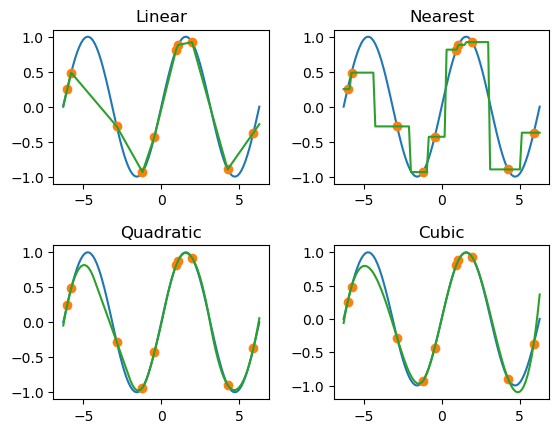

In [32]:
# code here

rng = np.random.default_rng(43)

def sinfunc(x):
    return np.sin(x)

res = 100
x_axis = np.linspace(-2*np.pi, 2*np.pi, num=res)

yvals = sinfunc(x_axis)
sample_x = rng.choice(x_axis)
sample_y = sinfunc(sample_x)

def synthdata(x_axis):
    synthdata_container = np.array([])
    xcoord_container = np.array([])
    
    for i in range(round(res*0.1)):
        xcoord = rng.choice(x_axis)
        sample = np.sin(xcoord)
        xcoord_container = np.append(xcoord_container, xcoord)
        synthdata_container = np.append(synthdata_container, sample)
    
    return xcoord_container, synthdata_container

xs, ys = synthdata(x_axis)

print(xs, ys)

#interpolating


interp1 = sp.interpolate.interp1d(xs, ys, kind="linear", bounds_error=False, fill_value="extrapolate")
ynew1 = interp1(x_axis)

interp2 = sp.interpolate.interp1d(xs, ys, kind="nearest", bounds_error=False, fill_value="extrapolate")
ynew2 = interp2(x_axis)

interp3 = sp.interpolate.interp1d(xs, ys, kind="quadratic", bounds_error=False, fill_value="extrapolate")
ynew3 = interp3(x_axis)

interp4 = sp.interpolate.interp1d(xs, ys, kind="cubic", bounds_error=False, fill_value="extrapolate")
ynew4 = interp4(x_axis)

#plotting

fig, ((ax1, ax2),(ax3, ax4)) = plt.subplots(2,2)
plt.subplots_adjust(wspace=0.3, hspace=0.4)

ax1.set_title("Linear")
ax1.plot(x_axis, yvals,)
ax1.plot(xs, ys, "o")
ax1.plot(x_axis, ynew1)

ax2.set_title("Nearest")
ax2.plot(x_axis, yvals,)
ax2.plot(xs, ys, "o")
ax2.plot(x_axis, ynew2)

ax3.set_title("Quadratic")
ax3.plot(x_axis, yvals,)
ax3.plot(xs, ys, "o")
ax3.plot(x_axis, ynew3)

ax4.set_title("Cubic")
ax4.plot(x_axis, yvals,)
ax4.plot(xs, ys, "o")
ax4.plot(x_axis, ynew4)

plt.savefig("sines.png")
plt.show()

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

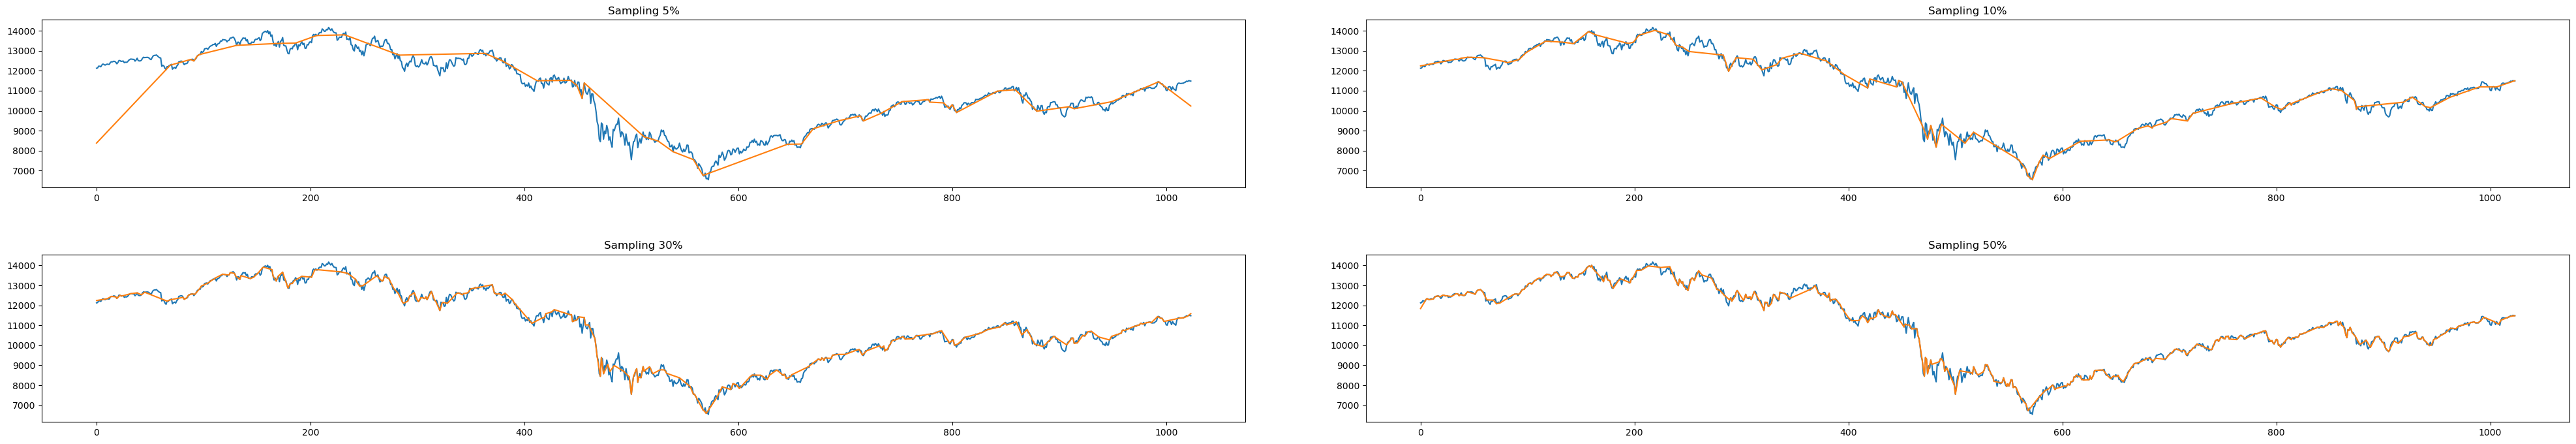

In [33]:
rng = np.random.default_rng(42)


dow = np.loadtxt("dow.txt")
x_axis = np.arange(dow.size)


def dowrand(frac, x_axis):

    xsamp_cont = np.array([])
    ysamp_cont = np.array([])

    for i in range(round(frac*x_axis.size)):
        xsamp = rng.choice(x_axis)    
        xsamp_cont = np.append(xsamp_cont, xsamp)
        ysamp = dow[xsamp] 
        ysamp_cont = np.append(ysamp_cont, ysamp)

    _, indices = np.unique(xsamp_cont, return_index = True)
    
    xsamp_cont = xsamp_cont[np.sort(indices)]
    ysamp_cont = ysamp_cont[np.sort(indices)]

    
    return xsamp_cont, ysamp_cont
xz, yz = dowrand(0.05, x_axis)
xz2, yz2 = dowrand(0.1, x_axis)
xz3, yz3 = dowrand(0.3, x_axis)
xz4, yz4 = dowrand(0.5, x_axis)

#interpolating

interpol1 = sp.interpolate.interp1d(xz, yz, kind="linear", bounds_error=False, fill_value="extrapolate")
yznew1 = interpol1(x_axis) 

interpol2 = sp.interpolate.interp1d(xz2, yz2, kind="linear", bounds_error=False, fill_value="extrapolate")
yznew2 = interpol2(x_axis) 

interpol3 = sp.interpolate.interp1d(xz3, yz3, kind="linear", bounds_error=False, fill_value="extrapolate")
yznew3 = interpol3(x_axis) 

interpol4 = sp.interpolate.interp1d(xz4, yz4, kind="linear", bounds_error=False, fill_value="extrapolate")
yznew4 = interpol4(x_axis) 


#plotting
fig, ((ax1,ax2),(ax3,ax4)) = plt.subplots(
    2,2,
    figsize=(50,8)
)

plt.subplots_adjust(wspace=0.1, hspace=0.4)


ax1.plot(dow)
ax2.plot(dow)
ax3.plot(dow)
ax4.plot(dow)


ax1.set_title("Sampling 5%")
ax1.plot(x_axis, yznew1)

ax2.plot(x_axis, yznew2)
ax2.set_title("Sampling 10%")

ax3.plot(x_axis, yznew3)
ax3.set_title("Sampling 30%")

ax4.plot(x_axis, yznew4)
ax4.set_title("Sampling 50%")

plt.savefig("percents.png")
plt.show()

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

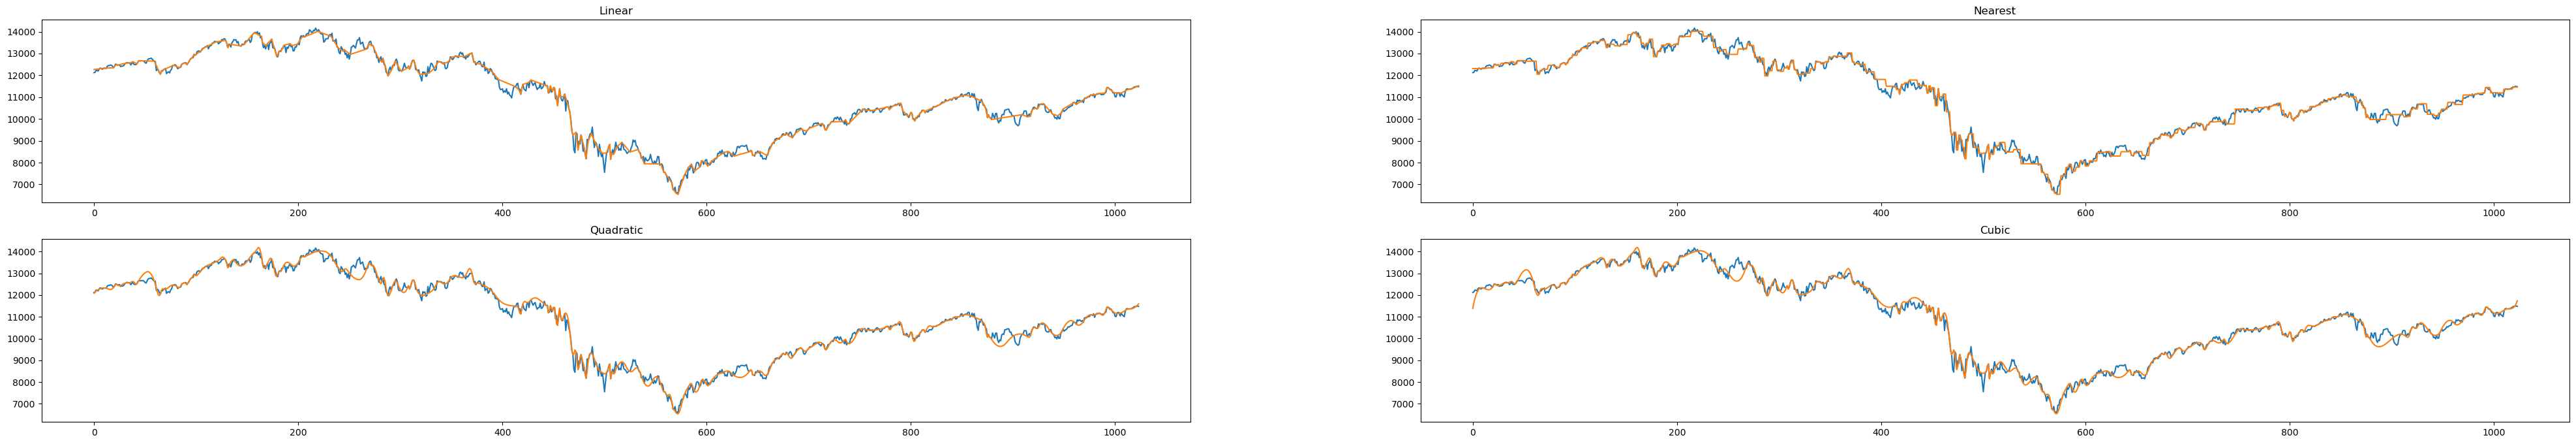

In [34]:
# code here

rng = np.random.default_rng(42)
dow = np.loadtxt("dow.txt")
x_axis = np.arange(dow.size)

xz3, yz3 = dowrand(0.3, x_axis)

interpola = sp.interpolate.interp1d(xz3, yz3, kind="linear", bounds_error=False, fill_value="extrapolate")
yznewa = interpola(x_axis) 

interpolb = sp.interpolate.interp1d(xz3, yz3, kind="nearest", bounds_error=False, fill_value="extrapolate")
yznewb = interpolb(x_axis) 

interpolc = sp.interpolate.interp1d(xz3, yz3, kind="quadratic", bounds_error=False, fill_value="extrapolate")
yznewc = interpolc(x_axis) 

interpold = sp.interpolate.interp1d(xz3, yz3, kind="cubic", bounds_error=False, fill_value="extrapolate")
yznewd = interpold(x_axis) 

fig, ((ax1,ax2),(ax3,ax4)) = plt.subplots(
    2,2,
    figsize=(50,8)
)

ax1.plot(dow)
ax2.plot(dow)
ax3.plot(dow)
ax4.plot(dow)

ax1.plot(x_axis, yznewa)
ax1.set_title("Linear")

ax2.plot(x_axis, yznewb)
ax2.set_title("Nearest")

ax3.plot(x_axis, yznewc)
ax3.set_title("Quadratic")

ax4.plot(x_axis, yznewd)
ax4.set_title("Cubic")

plt.savefig("dow.png")
plt.show()

### Problem  code summary


Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---